# India's Electricity Demand and Renewable Generation
### Where is the headroom for renewable energy?

**Perspective:** the analysis is written as if for a renewable-energy company (for example Tata Power) deciding **where and when to add generation capacity in India**. A PGDM Python project using numpy, pandas, matplotlib and seaborn.

**Questions**
1. How fast is electricity demand growing, and when and where does it peak?
2. How fast is renewable generation growing, and what is it made of?
3. How much of demand do renewables cover, and in which states is the share lowest?

**Data**
| Dataset | Content | Source |
|---|---|---|
| Demand | Daily consumption (million units, MU) by state, 6 Jan 2013 to 29 Sep 2024 | Kaggle: *India's Electricity Consumption Dataset* (https://www.kaggle.com/datasets/aryankhurana1701/state-wise-electricity-consumption-in-india), compiled from POSOCO / Grid-India daily reports |
| Renewable | Daily wind, solar, other and total renewable generation by state, 30 Oct 2019 to 27 Apr 2025 | India Data Portal, *Daily Renewable Energy Generation* (CEA data) (https://ckandev.indiadataportal.com/dataset/power/resource/f009766a-c8b1-4322-91dd-f13dd653b45b) |

**To run this notebook:** put `Indias_Electricity_Consumption_Dataset.csv` and `Renewable.csv` in the same folder as the notebook, then run all cells from the top. Charts are saved to an `images/` folder.

## 0. Setup

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sb

%matplotlib inline
os.makedirs('images', exist_ok=True)   # folder where the charts are saved

# Custom colour palette used by every chart (instead of the default blue/orange)
palette = ['#2A9D8F', '#E76F51', '#F4A261', '#9B72AA', '#264653', '#E9C46A', '#D1495B', '#8D99AE']
sb.set_palette(palette)

---
# Part 1: Demand data (2013 to Sep 2024)
## 1.1 Load and inspect

In [2]:
data1 = pd.read_csv('Indias_Electricity_Consumption_Dataset.csv')   # raw data, kept untouched
data1.head()

,Unnamed: 0,Dates,Andhra Pradesh,Arunachal Pradesh,Assam,Bihar,Chandigarh,Chhattisgarh,DD,Delhi,...,Punjab,Rajasthan,Sikkim,Tamil Nadu,Telangana,Tripura,UP,Uttarakhand,West Bengal,Total Consumption
0,0,2013-01-06,251.5,1.6,21.3,40.9,3.8,60.3,5.8,66.0,...,95.2,192.0,1.7,254.5,127.6,2.6,225.0,33.6,107.5,2845.7
1,1,2013-01-07,257.9,1.7,21.2,39.6,3.8,64.3,5.8,67.2,...,92.8,192.9,1.8,262.3,129.2,2.6,219.1,34.2,106.6,2876.7
2,2,2013-01-08,265.1,1.6,20.4,39.2,3.9,63.0,5.9,66.7,...,93.9,197.1,1.8,256.6,131.9,2.1,238.7,33.9,103.9,2923.0
3,3,2013-01-09,261.0,1.6,21.4,39.5,3.7,65.0,5.8,67.4,...,90.1,197.6,1.9,254.6,135.0,2.7,229.1,32.7,105.7,2912.1
4,4,2013-01-10,260.0,1.6,21.1,39.7,3.8,66.5,5.9,67.8,...,93.5,199.9,1.9,255.3,130.0,3.2,224.5,35.4,105.3,2920.8


In [3]:
data1.tail()

,Unnamed: 0,Dates,Andhra Pradesh,Arunachal Pradesh,Assam,Bihar,Chandigarh,Chhattisgarh,DD,Delhi,...,Punjab,Rajasthan,Sikkim,Tamil Nadu,Telangana,Tripura,UP,Uttarakhand,West Bengal,Total Consumption
3702,3702,2024-09-25,204.9,2.5,45.1,131.7,7.4,117.1,NaN,140.0,...,340.1,354.8,1.4,384.0,213.8,NaN,542.3,51.6,195.8,4969.5
3703,3703,2024-09-26,205.6,2.6,36.0,108.9,6.3,111.9,NaN,133.6,...,320.6,347.1,1.4,388.9,213.6,NaN,486.9,50.1,178.0,4744.7
3704,3704,2024-09-27,208.6,2.6,40.1,96.3,5.7,107.1,NaN,129.6,...,281.4,341.1,1.2,389.8,229.6,NaN,400.8,48.6,181.1,4589.9
3705,3705,2024-09-28,212.9,2.8,38.5,100.9,5.3,109.9,NaN,116.9,...,248.0,324.1,1.1,390.9,247.8,NaN,383.8,47.2,195.9,4510.7
3706,3706,2024-09-29,212.7,2.8,37.8,118.0,5.1,116.5,NaN,113.4,...,245.2,318.2,1.0,352.2,258.4,NaN,399.8,44.1,203.9,4457.8


In [4]:
data1.shape

(3707, 39)

In [5]:
data1.info()

<class 'pandas.DataFrame'>
RangeIndex: 3707 entries, 0 to 3706
Data columns (total 39 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Unnamed: 0         3707 non-null   int64  
 1   Dates              3707 non-null   str    
 2   Andhra Pradesh     3707 non-null   float64
 3   Arunachal Pradesh  3707 non-null   float64
 4   Assam              3707 non-null   float64
 5   Bihar              3707 non-null   float64
 6   Chandigarh         3707 non-null   float64
 7   Chhattisgarh       3707 non-null   float64
 8   DD                 3000 non-null   float64
 9   Delhi              3707 non-null   float64
 10  DNH                2995 non-null   float64
 11  DVC                3707 non-null   float64
 12  Essar steel        3175 non-null   float64
 13  Goa                3707 non-null   float64
 14  Gujarat            3707 non-null   float64
 15  Haryana            3707 non-null   float64
 16  HP                 3707 non-null   

The file has **3,707 rows and 39 columns**: one row per day and one column per state (daily consumption in million units, MU), plus `Total Consumption`. It runs from 6 Jan 2013 to 29 Sep 2024. `Dates` is stored as text and `Unnamed: 0` is a leftover index column, so both need fixing.

## 1.2 Cleaning

In [6]:
df = data1.copy()                        # working copy: the raw data1 stays untouched
df = df.drop(columns=['Unnamed: 0'])     # leftover index column
df['Dates'] = pd.to_datetime(df['Dates'])
df = df.set_index('Dates')               # dates become the row labels
df.head()

,Andhra Pradesh,Arunachal Pradesh,Assam,Bihar,Chandigarh,Chhattisgarh,DD,Delhi,DNH,DVC,...,Punjab,Rajasthan,Sikkim,Tamil Nadu,Telangana,Tripura,UP,Uttarakhand,West Bengal,Total Consumption
Dates,,,,,,,,,,,,,,,,,,,,,
2013-01-06,251.5,1.6,21.3,40.9,3.8,60.3,5.8,66.0,15.0,56.2,...,95.2,192.0,1.7,254.5,127.6,2.6,225.0,33.6,107.5,2845.7
2013-01-07,257.9,1.7,21.2,39.6,3.8,64.3,5.8,67.2,15.1,59.9,...,92.8,192.9,1.8,262.3,129.2,2.6,219.1,34.2,106.6,2876.7
2013-01-08,265.1,1.6,20.4,39.2,3.9,63.0,5.9,66.7,15.2,60.3,...,93.9,197.1,1.8,256.6,131.9,2.1,238.7,33.9,103.9,2923.0
2013-01-09,261.0,1.6,21.4,39.5,3.7,65.0,5.8,67.4,15.2,60.0,...,90.1,197.6,1.9,254.6,135.0,2.7,229.1,32.7,105.7,2912.1
2013-01-10,260.0,1.6,21.1,39.7,3.8,66.5,5.9,67.8,14.9,58.9,...,93.5,199.9,1.9,255.3,130.0,3.2,224.5,35.4,105.3,2920.8


In [7]:
print('Dates in order:', df.index.is_monotonic_increasing)
print('Duplicate dates:', df.index.duplicated().sum())

Dates in order: True
Duplicate dates: 0


The dates are in order and none repeats, so the series can be used for time-based work.

## 1.3 Data quality: missing dates and empty columns

In [8]:
full_range = pd.date_range(df.index.min(), df.index.max(), freq='D')   # every calendar day
missing_dates = full_range.difference(df.index)                         # days that should exist but do not
print('Calendar days:', len(full_range))
print('Days in data :', len(df))
print('Missing days :', len(missing_dates))

Calendar days: 4285
Days in data : 3707
Missing days : 578


In [9]:
missing_dates.year.value_counts().sort_index()

2013    207
2014     77
2015     80
2016      6
2017      2
2019      1
2020     51
2021     14
2022     34
2023     99
2024      7
Name: count, dtype: int64

In [10]:
missing_dates[missing_dates.year == 2023].month.value_counts().sort_index()

1     31
2     28
3     26
4      7
11     4
12     3
Name: count, dtype: int64

**578 of 4,285 calendar days are missing.** They are concentrated in a few years (2013: 207, 2023: 99, 2015: 80, 2014: 77, 2020: 51). In 2023, January, February and most of March are absent (31 + 28 + 26 days), which is a block and not scattered days. The gaps are **not filled**, because filling months of data with estimates would invent numbers; averages are taken over the days that exist.

In [11]:
missing_counts = df.isnull().sum()
missing_counts[missing_counts > 0]       # only the columns that have empty cells

DD                    707
DNH                   712
Essar steel           532
Meghalaya              14
Pondy                2078
Tripura              1742
Total Consumption       6
dtype: int64

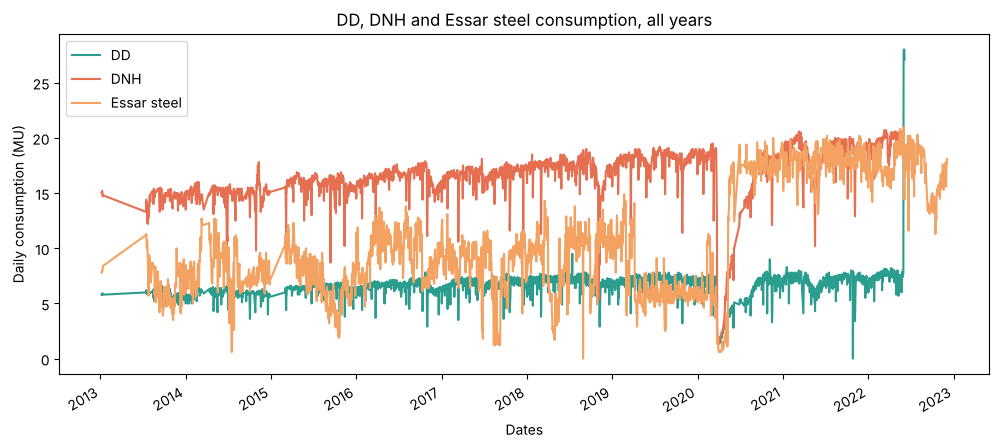

In [12]:
df[['DD', 'DNH', 'Essar steel']].plot(figsize=(12, 5), title='DD, DNH and Essar steel consumption, all years')
plt.ylabel('Daily consumption (MU)')
plt.show()

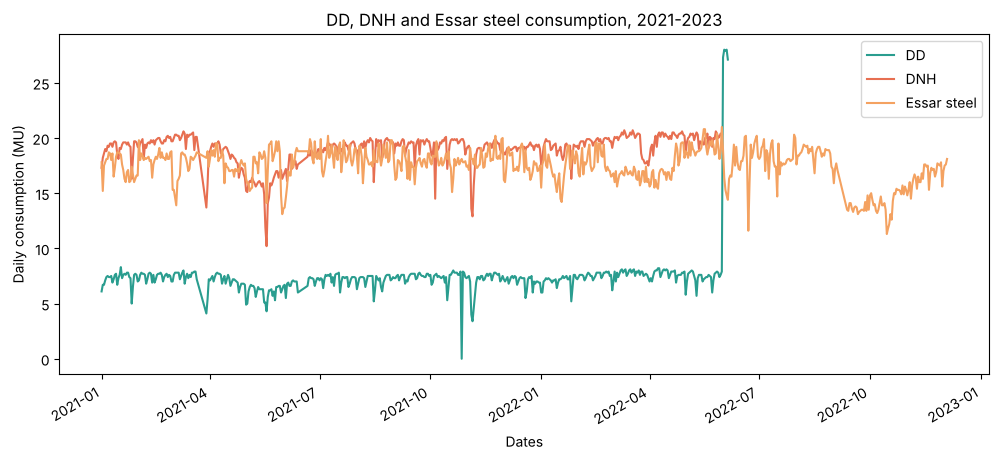

In [13]:
df.loc['2021':'2023', ['DD', 'DNH', 'Essar steel']].plot(figsize=(12, 5), title='DD, DNH and Essar steel consumption, 2021-2023')
plt.ylabel('Daily consumption (MU)')
plt.show()

In [14]:
for col in ['DD', 'DNH', 'Essar steel', 'Pondy', 'Tripura']:
    print(col, 'last value on', df[col].dropna().index[-1].date())   # last date with data

DD last value on 2022-06-05
DNH last value on 2022-05-31
Essar steel last value on 2022-12-04
Pondy last value on 2020-11-14
Tripura last value on 2024-03-31


Five columns stop reporting or have long gaps: **DD** (last value 5 Jun 2022), **DNH** (31 May 2022), **Essar steel** (4 Dec 2022), **Pondy** (14 Nov 2020) and **Tripura** (31 Mar 2024, and mostly empty in 2021 and 2022). DD and DNH are reported separately until May 2022, and DD's later values (about 27) look like a combined figure (DD is normally about 7 and DNH about 20). Essar steel is a steel plant, not a state. None of the five is among the top 10 demand states, and they are **not used in the state-level analysis**.

In [15]:
parts_sum = df.drop(columns='Total Consumption').sum(axis=1)     # sum of the columns that are available
(df['Total Consumption'] / parts_sum).groupby(df.index.year).mean().round(3)

Dates
2013    1.000
2014    1.000
2015    1.000
2016    1.000
2017    1.001
2018    1.001
2019    1.001
2020    1.002
2021    1.002
2022    1.006
2023    1.017
2024    1.016
dtype: float64

`Total Consumption` equals the sum of the columns until about 2015 and then drifts to about 1.7% above it by 2023. That gap is about the size of the small entities that stopped reporting, which suggests the total is still a full national figure even though some columns went empty. The source's method was not independently checked.

In [16]:
df[df['Total Consumption'].isnull()].index

DatetimeIndex(['2023-04-24', '2023-04-25', '2023-04-26', '2023-04-27',
               '2023-04-28', '2023-04-29'],
              dtype='datetime64[us]', name='Dates', freq=None)

`Total Consumption` is missing for 24 to 29 April 2023 (6 days). They are left empty, as they are too few to affect the results.

## 1.4 Demand trends

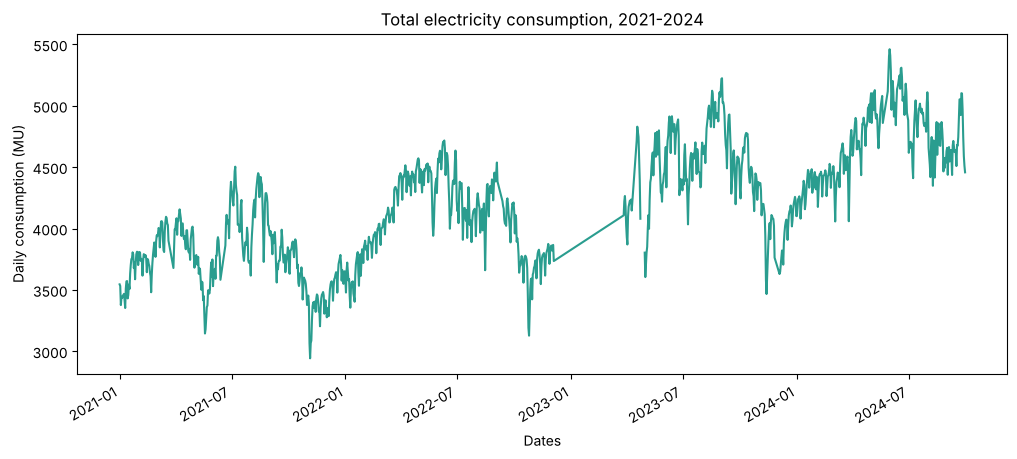

In [17]:
df.loc['2021':'2024', 'Total Consumption'].plot(figsize=(12, 5), title='Total electricity consumption, 2021-2024')
plt.ylabel('Daily consumption (MU)')
plt.show()

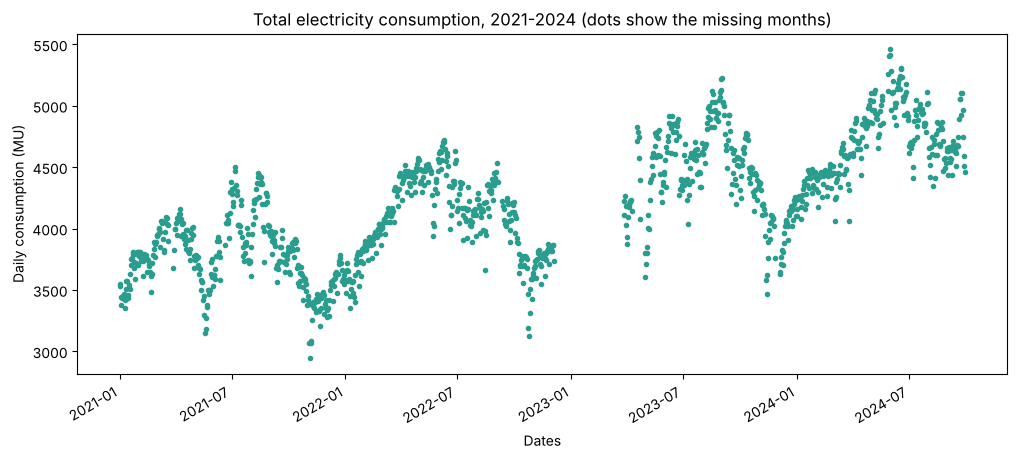

In [18]:
df.loc['2021':'2024', 'Total Consumption'].plot(style='.', figsize=(12, 5), title='Total electricity consumption, 2021-2024 (dots show the missing months)')
plt.ylabel('Daily consumption (MU)')
plt.savefig('images/total_consumption_2021_2024.png', dpi=150, bbox_inches='tight')
plt.show()

Demand follows a repeating yearly wave, and the peaks rise from year to year. The straight line in the first chart across early 2023 is not data: it is the missing January to March block joined up by the plotting library, which the dot version shows honestly as an empty stretch.

In [19]:
df['Total Consumption'].groupby(df.index.year).idxmax()   # date of the highest day in each year

Dates
2013   2013-09-05
2014   2014-04-29
2015   2015-07-15
2016   2016-09-10
2017   2017-08-18
2018   2018-09-19
2019   2019-05-30
2020   2020-09-09
2021   2021-07-07
2022   2022-06-10
2023   2023-09-02
2024   2024-05-30
Name: Total Consumption, dtype: datetime64[us]

The yearly peak falls between April and September, with no fixed month: six years peak in April to July and six in August to September. This variation may relate to weather, which this dataset cannot confirm.

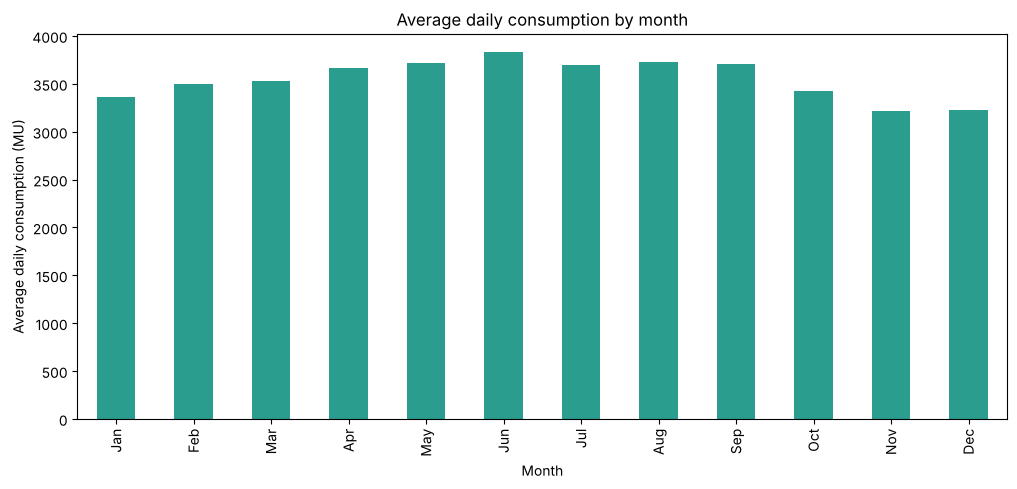

In [20]:
monthly = df['Total Consumption'].groupby(df.index.month).mean()
monthly.index = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
monthly.plot(kind='bar', figsize=(12, 5), title='Average daily consumption by month')
plt.xlabel('Month')
plt.ylabel('Average daily consumption (MU)')
plt.savefig('images/demand_by_month.png', dpi=150, bbox_inches='tight')
plt.show()

On average, consumption is highest in May to September (peak in June, about 3,830 MU/day) and lowest in November to December (about 3,220 MU/day), roughly 16% lower than June (June is about 19% above November).

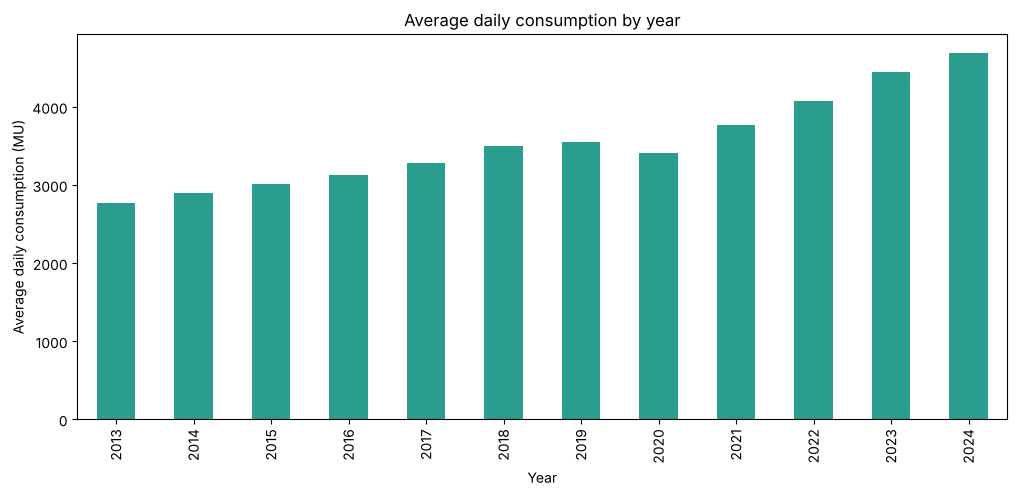

In [21]:
yearly = df['Total Consumption'].groupby(df.index.year).mean()
yearly.plot(kind='bar', figsize=(12, 5), title='Average daily consumption by year')
plt.xlabel('Year')
plt.ylabel('Average daily consumption (MU)')
plt.savefig('images/demand_by_year.png', dpi=150, bbox_inches='tight')
plt.show()

In [22]:
yearly.round(1)

Dates
2013    2771.4
2014    2902.6
2015    3011.0
2016    3128.4
2017    3279.6
2018    3504.1
2019    3547.3
2020    3413.4
2021    3771.0
2022    4081.7
2023    4447.4
2024    4693.3
Name: Total Consumption, dtype: float64

In [23]:
(yearly.pct_change() * 100).round(1)   # year-on-year change in %

Dates
2013     NaN
2014     4.7
2015     3.7
2016     3.9
2017     4.8
2018     6.8
2019     1.2
2020    -3.8
2021    10.5
2022     8.2
2023     9.0
2024     5.5
Name: Total Consumption, dtype: float64

Average daily consumption grew from about **2,771 MU (2013) to 4,693 MU (2024)**, roughly +69% or about 4.9% a year. Demand fell 3.8% in 2020 (COVID-19 lockdown) and rebounded 10.5% in 2021; growth stayed high in 2022 and 2023 (8 to 9%). The 2023 and 2024 averages are slightly overstated, because 2023 lacks January to March and 2024 ends in September (both months with lower demand).

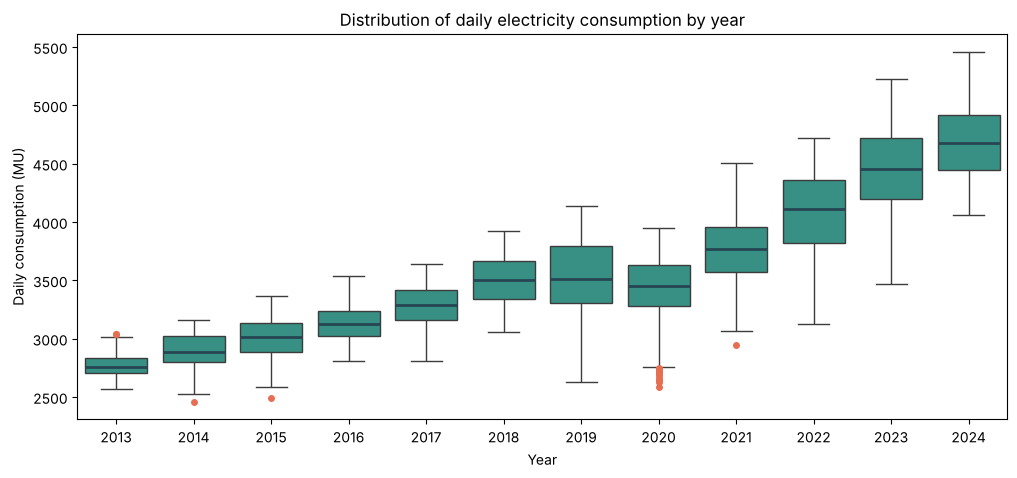

In [24]:
plt.figure(figsize=(12, 5))
sb.boxplot(x=df.index.year, y=df['Total Consumption'], color=palette[0],
           medianprops={'color': palette[4], 'linewidth': 2},
           flierprops={'markerfacecolor': palette[1], 'markeredgecolor': palette[1], 'markersize': 4})
plt.xlabel('Year')
plt.ylabel('Daily consumption (MU)')
plt.title('Distribution of daily electricity consumption by year')
plt.savefig('images/demand_boxplot_by_year.png', dpi=150, bbox_inches='tight')
plt.show()

The box plot shows how daily consumption is spread within each year: the box holds the middle half of the days, the line is the median and the dots are unusually high or low days. The **median rises from about 2,758 MU (2013) to about 4,674 MU (2024)**, and the **boxes get taller**: the middle half of days spans about 127 MU in 2013 and about 465 MU in 2024 (the widest is about 541 MU in 2022), so the gap between low and high days within a year has grown along with demand. **2020 shows a cluster of low outliers**: 14 days between 26 March and 27 April, which matches the COVID-19 lockdown period.

## 1.5 Which states drive demand?

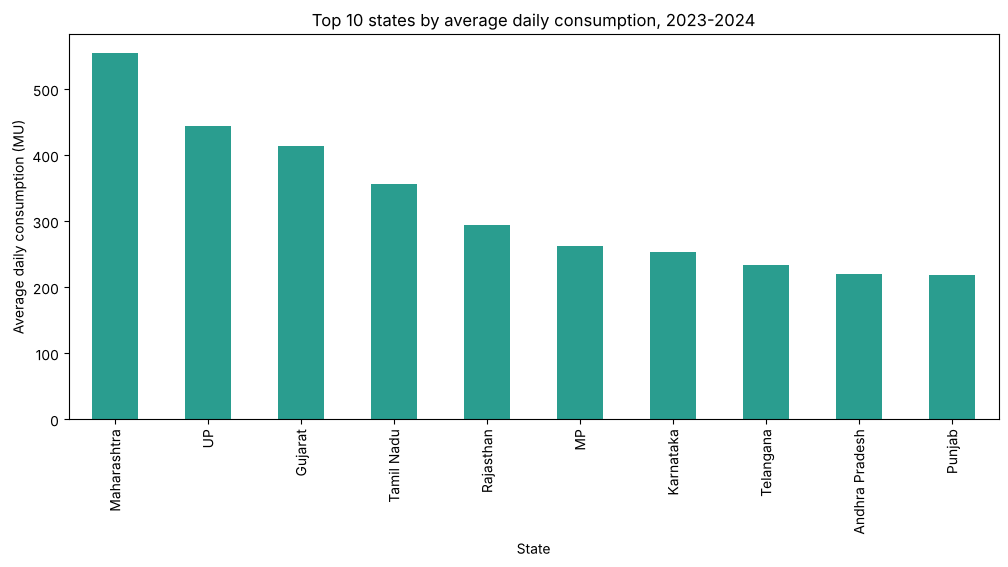

Maharashtra       555.3
UP                443.9
Gujarat           413.8
Tamil Nadu        356.4
Rajasthan         294.4
MP                263.4
Karnataka         253.8
Telangana         233.8
Andhra Pradesh    220.9
Punjab            218.1
dtype: float64

In [25]:
state_avg = df.loc['2023':'2024'].mean()           # average of every column over 2023-2024
state_avg = state_avg.drop('Total Consumption')    # the total is not a state
top_10 = state_avg.sort_values(ascending=False).head(10)
top_10.plot(kind='bar', figsize=(12, 5), title='Top 10 states by average daily consumption, 2023-2024')
plt.xlabel('State')
plt.ylabel('Average daily consumption (MU)')
plt.savefig('images/top10_states_demand.png', dpi=150, bbox_inches='tight')
plt.show()
top_10.round(1)

Maharashtra consumes the most (about 555 MU/day), followed by UP (444) and Gujarat (414). The averages cover April 2023 to September 2024, because January to March 2023 is missing for every state. `DD`, `DNH`, `DVC` and `Essar steel` are not in the top 10.

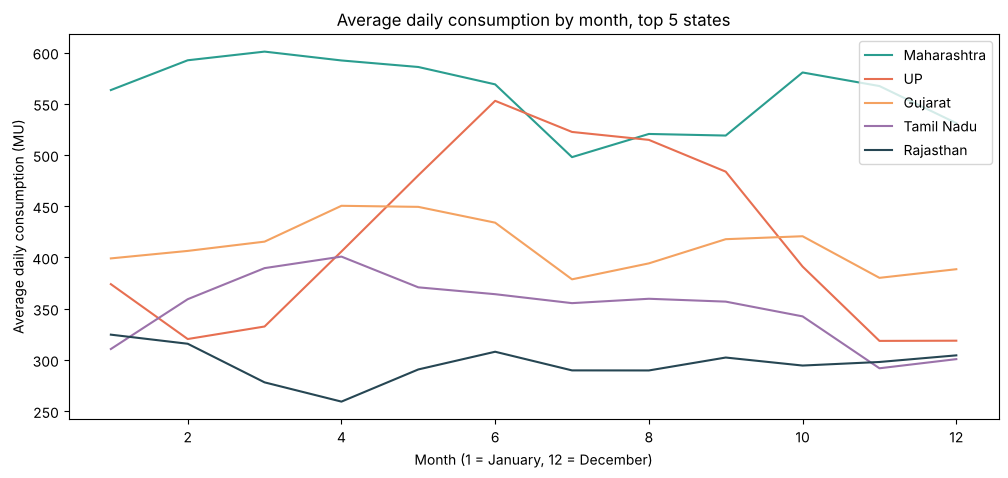

In [26]:
recent = df.loc['2023':'2024']
recent[top_10.index[:5]].groupby(recent.index.month).mean().plot(figsize=(12, 5), title='Average daily consumption by month, top 5 states')
plt.xlabel('Month (1 = January, 12 = December)')
plt.ylabel('Average daily consumption (MU)')
plt.savefig('images/top5_states_monthly.png', dpi=150, bbox_inches='tight')
plt.show()

In [27]:
monthly5 = recent[top_10.index[:5]].groupby(recent.index.month).mean()
(monthly5.max() / monthly5.min()).round(2)     # highest month divided by lowest month

Maharashtra    1.21
UP             1.74
Gujarat        1.19
Tamil Nadu     1.37
Rajasthan      1.25
dtype: float64

States follow different seasonal patterns. **UP is the most seasonal** of the top five (its highest month is about 74% above its lowest), while Gujarat and Maharashtra are the least (about 19 to 21%). The all-India June peak is therefore a blend of different state patterns.

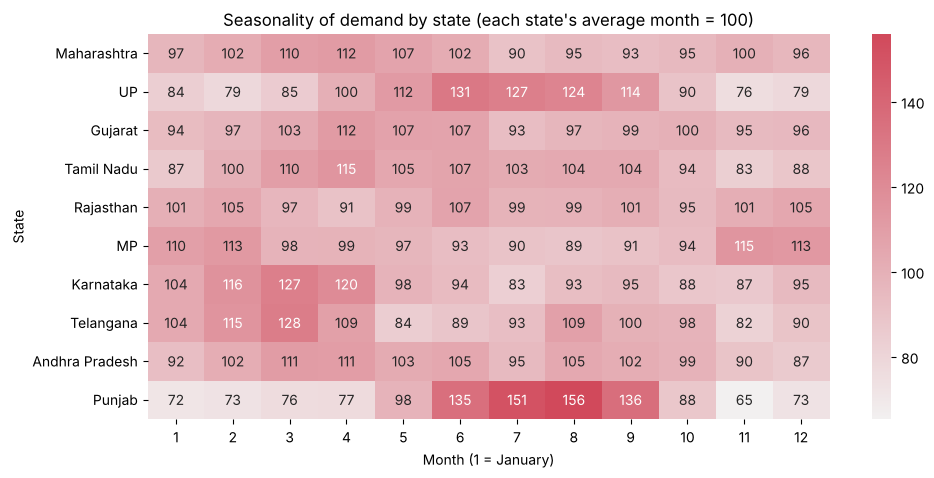

In [28]:
d = df.loc['2021':'2024', top_10.index]
heat = d.groupby(d.index.month).mean().T                 # states as rows, months as columns
heat = heat.div(heat.mean(axis=1), axis=0) * 100         # each state's average month = 100

plt.figure(figsize=(11, 5))
sb.heatmap(heat, cmap=sb.light_palette(palette[6], as_cmap=True), annot=True, fmt='.0f')
plt.xlabel('Month (1 = January)')
plt.ylabel('State')
plt.title("Seasonality of demand by state (each state's average month = 100)")
plt.savefig('images/seasonality_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

**Punjab has the biggest swing**: from 65 (November) to 156 (August), about 2.4 times, with demand concentrated in July to September. UP follows (76 to 131). Karnataka and Telangana peak in March, Tamil Nadu, Gujarat and Maharashtra in April, while Maharashtra, Gujarat and Karnataka have their lowest mid-year month in July (monsoon). MP peaks in winter, and Rajasthan is the flattest. 2021 to 2024 is not evenly covered across months (January to March 2023 and October to December 2024 are missing), so small differences between months should not be over-read.

## 1.6 A simple trend baseline

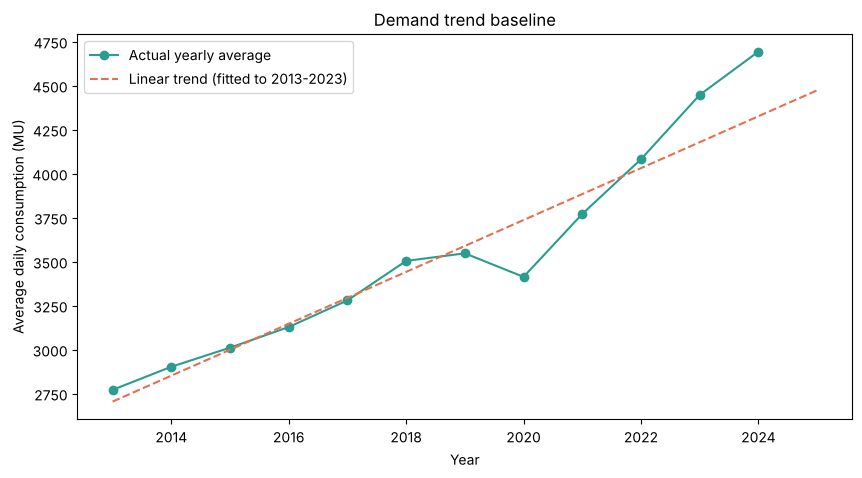

Slope (MU per year): 147.4
Trend value for 2025: 4473.4


In [29]:
full_years = yearly.loc[:2023]                                   # 2024 is a partial year
slope, intercept = np.polyfit(full_years.index, full_years.values, 1)   # best straight line

years = np.arange(2013, 2026)
trend = slope * years + intercept

plt.figure(figsize=(10, 5))
plt.plot(yearly.index, yearly.values, marker='o', label='Actual yearly average')
plt.plot(years, trend, linestyle='--', label='Linear trend (fitted to 2013-2023)')
plt.xlabel('Year')
plt.ylabel('Average daily consumption (MU)')
plt.title('Demand trend baseline')
plt.legend()
plt.savefig('images/demand_trend.png', dpi=150, bbox_inches='tight')
plt.show()
print('Slope (MU per year):', round(slope, 1))
print('Trend value for 2025:', round(slope * 2025 + intercept, 1))

A straight-line trend fitted to 2013 to 2023 adds about **147 MU per year** and projects about 4,473 MU/day for 2025. Actual demand since 2021 has run above this line (2024 averages about 4,693 MU/day, though it covers January to September only), so the line **understates recent growth**. It is a simple baseline, not a forecast.

---
# Part 2: Renewable generation (Oct 2019 to Apr 2025) and how it compares with demand
## 2.1 Load, inspect and clean

In [30]:
renew = pd.read_csv('Renewable.csv')   # raw data, kept untouched
renew.shape

(67014, 9)

In [31]:
renew.head()

,id,date,state_name,state_code,region,wind_energy,solar_energy,other_renewable_energy,total_renewable_energy
0,0,2019-10-30,All India,99,NaN,100.68,74.39,19.27,194.34
1,1,2019-10-30,Andhra Pradesh,28,Southern Region,10.66,3.91,0.00,14.57
2,2,2019-10-30,Arunachal Pradesh,12,North-Eastern Region,0.00,0.00,0.00,0.00
3,3,2019-10-30,Assam,18,North-Eastern Region,0.00,0.00,0.00,0.00
4,4,2019-10-30,Bihar,10,Eastern Region,0.00,0.00,0.40,0.40


In [32]:
renew.info()

<class 'pandas.DataFrame'>
RangeIndex: 67014 entries, 0 to 67013
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   id                      67014 non-null  int64  
 1   date                    67014 non-null  str    
 2   state_name              67014 non-null  str    
 3   state_code              67014 non-null  int64  
 4   region                  65090 non-null  str    
 5   wind_energy             67014 non-null  float64
 6   solar_energy            67013 non-null  float64
 7   other_renewable_energy  67010 non-null  float64
 8   total_renewable_energy  67014 non-null  float64
dtypes: float64(4), int64(2), str(3)
memory usage: 4.6 MB


The file is in **long format**: one row per state per day (67,014 rows), with the state in `state_name`. It also contains an **All India** row for each day, which is the national total. `region` is empty only for those national rows. `total_renewable_energy` is wind + solar + other and has no missing values.

In [33]:
rdf = renew.copy()
rdf['date'] = pd.to_datetime(rdf['date'])
india = rdf[rdf['state_name'] == 'All India'].set_index('date')   # national rows
states = rdf[rdf['state_name'] != 'All India']                    # one row per state per day
print(india.shape, states.shape)
print('Duplicate national dates:', india.index.duplicated().sum())

(1924, 8) (65090, 9)
Duplicate national dates: 0


In [34]:
# Sanity check: the All India row should equal the sum of the states
check = states[states['date'].dt.year == 2024].groupby('date')['total_renewable_energy'].sum().mean()
print(round(check, 1), round(india.loc['2024', 'total_renewable_energy'].mean(), 1))

583.2 583.2


The two numbers match, so the All India rows are a proper total. They are kept separate from the state rows so that nothing is counted twice.

## 2.2 Data quality: missing days

In [35]:
full_range_renewable = pd.date_range(india.index.min(), india.index.max(), freq='D')
missing_renewable = full_range_renewable.difference(india.index)
print('Calendar days:', len(full_range_renewable))
print('Missing days :', len(missing_renewable))

Calendar days: 2007
Missing days : 83


In [36]:
missing_renewable.year.value_counts().sort_index()

2019     5
2020    59
2021    15
2022     4
Name: count, dtype: int64

In [37]:
missing_renewable[missing_renewable.year == 2020].month.value_counts().sort_index()

1     1
2    27
3    25
4     1
5     1
6     4
Name: count, dtype: int64

In [38]:
m2020 = missing_renewable[missing_renewable.year == 2020]
m2020

DatetimeIndex(['2020-01-10', '2020-02-03', '2020-02-04', '2020-02-05',
               '2020-02-06', '2020-02-07', '2020-02-08', '2020-02-09',
               '2020-02-10', '2020-02-11', '2020-02-12', '2020-02-13',
               '2020-02-14', '2020-02-15', '2020-02-16', '2020-02-17',
               '2020-02-18', '2020-02-19', '2020-02-20', '2020-02-21',
               '2020-02-22', '2020-02-23', '2020-02-24', '2020-02-25',
               '2020-02-26', '2020-02-27', '2020-02-28', '2020-02-29',
               '2020-03-01', '2020-03-03', '2020-03-04', '2020-03-05',
               '2020-03-06', '2020-03-07', '2020-03-08', '2020-03-09',
               '2020-03-10', '2020-03-11', '2020-03-12', '2020-03-13',
               '2020-03-14', '2020-03-15', '2020-03-21', '2020-03-22',
               '2020-03-23', '2020-03-24', '2020-03-25', '2020-03-26',
               '2020-03-27', '2020-03-28', '2020-03-29', '2020-03-30',
               '2020-03-31', '2020-04-15', '2020-05-31', '2020-06-01',
      

The renewable file is missing **83 days**, mostly one block: nothing from 3 Feb to 31 Mar 2020 apart from 6 days (2 Mar and 16 to 20 Mar), which includes the start of the COVID lockdown. 2023, 2024 and 2025 have no gaps. The 2020 average is therefore **not comparable** with later years, and year-by-year comparisons use **2021 to 2024**.

## 2.3 Renewable growth and its share of demand

In [39]:
yearly_renew = india['total_renewable_energy'].groupby(india.index.year).mean()
yearly_renew.round(1)

date
2019    262.0
2020    339.7
2021    377.5
2022    466.7
2023    530.5
2024    583.2
2025    647.2
Name: total_renewable_energy, dtype: float64

In [40]:
(yearly_renew.loc[2021:2024].pct_change() * 100).round(1)   # growth, 2021 to 2024 only

date
2021     NaN
2022    23.6
2023    13.7
2024     9.9
Name: total_renewable_energy, dtype: float64

In [41]:
comparison = pd.DataFrame({'Demand': yearly, 'Renewable': yearly_renew})
comparison = comparison.loc[2021:2024]
comparison['Renewable share of Demand (%)'] = (comparison['Renewable'] / comparison['Demand'] * 100).round(1)
comparison.round(1)

,Demand,Renewable,Renewable share of Demand (%)
2021,3771.0,377.5,10.0
2022,4081.7,466.7,11.4
2023,4447.4,530.5,11.9
2024,4693.3,583.2,12.4


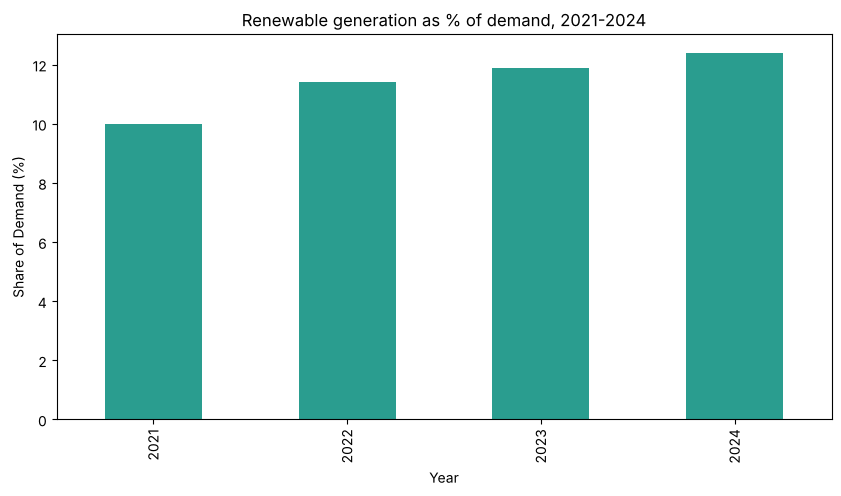

In [42]:
comparison['Renewable share of Demand (%)'].plot(kind='bar', figsize=(10, 5), title='Renewable generation as % of demand, 2021-2024')
plt.xlabel('Year')
plt.ylabel('Share of Demand (%)')
plt.savefig('images/renewable_share_of_demand.png', dpi=150, bbox_inches='tight')
plt.show()

All-India renewable generation averaged about **378 MU/day in 2021 and 583 in 2024 (+54%)**, against about +24% for demand over the same years. Renewables' share of demand rose from **10.0% to 12.4%**, but the yearly gain slowed from 1.4 to 0.5 percentage points. Demand rose by about 922 MU/day over these years and renewables by about 206, so renewables covered roughly **22% of the growth in demand**, and about 88% of demand is still met by other sources. Both datasets are separate sources and the units were not independently confirmed, so the figures are indicative. 2019, 2020 and 2025 are excluded because they are incomplete.

## 2.4 What is renewable generation made of?

In [43]:
src = india.loc['2021':'2024', ['wind_energy', 'solar_energy', 'other_renewable_energy']]
mix = src.groupby(src.index.year).mean().round(1)
source_colors = [palette[0], palette[2], palette[3]]   # wind, solar, other (same colours in the bar and pie charts)
mix

,wind_energy,solar_energy,other_renewable_energy
date,,,
2021,173.4,175.0,29.2
2022,185.7,240.9,40.0
2023,217.6,288.3,24.6
2024,214.8,341.1,27.2


In [44]:
(mix.div(mix.sum(axis=1), axis=0) * 100).round(1)   # each source as % of the yearly total

,wind_energy,solar_energy,other_renewable_energy
date,,,
2021,45.9,46.3,7.7
2022,39.8,51.6,8.6
2023,41.0,54.3,4.6
2024,36.8,58.5,4.7


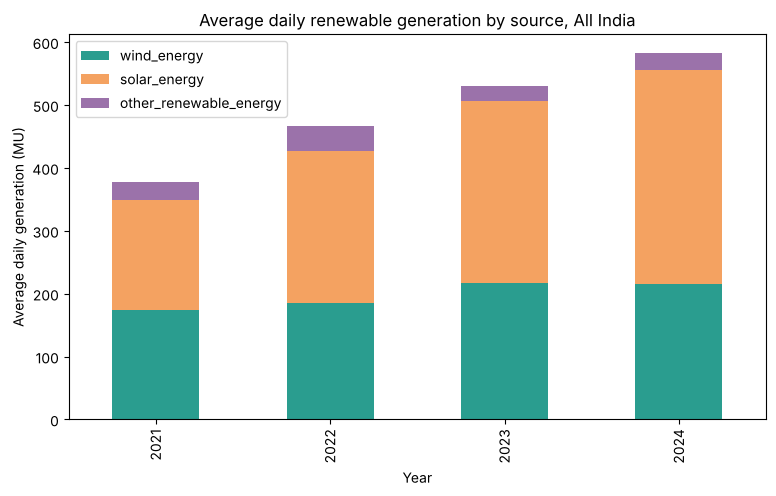

In [45]:
mix.plot(kind='bar', stacked=True, figsize=(9, 5), title='Average daily renewable generation by source, All India', color=source_colors)
plt.xlabel('Year')
plt.ylabel('Average daily generation (MU)')
plt.savefig('images/renewable_by_source.png', dpi=150, bbox_inches='tight')
plt.show()

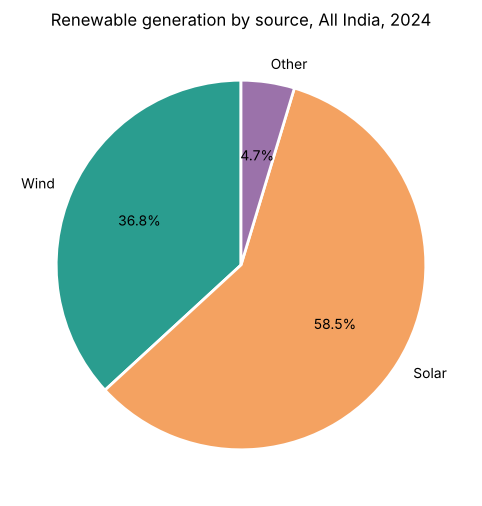

In [46]:
src24 = mix.loc[2024]                      # wind, solar, other for 2024
plt.figure(figsize=(6, 6))
plt.pie(src24.values, labels=['Wind', 'Solar', 'Other'], colors=source_colors,
        autopct='%1.1f%%', startangle=90,
        wedgeprops={'edgecolor': 'white', 'linewidth': 2})
plt.title('Renewable generation by source, All India, 2024')
plt.savefig('images/renewable_source_pie.png', dpi=150, bbox_inches='tight')
plt.show()

**Solar is driving the growth.** Solar generation rose from about 175 MU/day (2021) to about 341 (2024), roughly +95%, while wind rose from about 173 to 215 (+24%) and was flat in 2024. Solar's share of renewable generation went from about 46% to about 58%, and wind's fell from about 46% to about 37%. The pie chart shows the 2024 split: solar 58.5%, wind 36.8% and other 4.7%.

## 2.5 Which states generate renewable power, and where is it growing?

In [47]:
s = states.copy()
s['year'] = s['date'].dt.year      # .dt pulls the year out of a date column
by_year = s[s['year'].between(2021, 2024)].groupby(['state_name', 'year'])['total_renewable_energy'].mean().unstack()
by_year['Growth %'] = ((by_year[2024] / by_year[2021] - 1) * 100).round(0)
by_year['Gain (MU/day)'] = (by_year[2024] - by_year[2021]).round(1)
by_year.sort_values(2024, ascending=False).head(10).round(1)

year,2021,2022,2023,2024,Growth %,Gain (MU/day)
state_name,,,,,,
Rajasthan,55.3,102.1,126.4,146.2,165.0,91.0
Gujarat,62.5,76.7,96.8,114.6,83.0,52.1
Tamil Nadu,54.9,63.1,74.9,81.4,48.0,26.5
Karnataka,69.2,79.8,75.4,77.4,12.0,8.2
Andhra Pradesh,38.1,40.4,44.0,41.7,9.0,3.6
Maharashtra,24.3,28.3,34.2,35.3,45.0,11.0
Madhya Pradesh,23.3,23.7,23.2,27.0,16.0,3.8
Telangana,18.4,18.7,19.5,18.8,2.0,0.4
Uttar Pradesh,9.1,9.4,11.1,12.1,33.0,3.0


In [48]:
share_nat = by_year[2024] / by_year[2024].sum() * 100        # each state's share of national generation, 2024
share_nat.sort_values(ascending=False).head(6).round(1)

state_name
Rajasthan         25.1
Gujarat           19.6
Tamil Nadu        14.0
Karnataka         13.3
Andhra Pradesh     7.2
Maharashtra        6.0
Name: 2024, dtype: float64

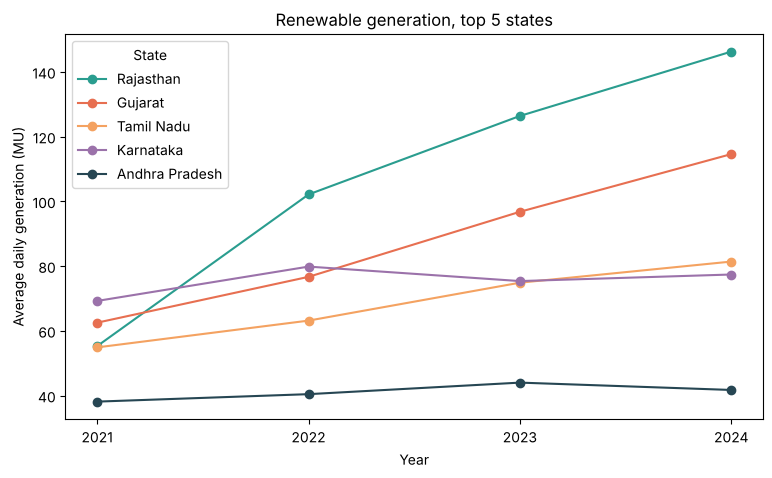

In [49]:
top5 = by_year.sort_values(2024, ascending=False).head(5)[[2021, 2022, 2023, 2024]]   # top 5 states, one column per year
yrs = [2021, 2022, 2023, 2024]

plt.figure(figsize=(9, 5))
for state in top5.index:
    plt.plot(yrs, top5.loc[state].values, marker='o', label=state)      # one line per state
plt.xticks(yrs)
plt.xlabel('Year')
plt.ylabel('Average daily generation (MU)')
plt.title('Renewable generation, top 5 states')
plt.legend(title='State')
plt.savefig('images/top5_renewable_states.png', dpi=150, bbox_inches='tight')
plt.show()

Generation is **concentrated in a few states**. Rajasthan, Gujarat, Tamil Nadu and Karnataka produce about 72% of India's renewable generation (Rajasthan alone about 25%). Rajasthan, Gujarat and Tamil Nadu also account for about 82% of the national gain from 2021 to 2024 (Rajasthan +91 MU/day, Gujarat +52, Tamil Nadu +27), while Karnataka, Andhra Pradesh and Telangana have barely grown (+12%, +9%, +2%). Percentage growth can mislead for states with a tiny base (Chhattisgarh is +222% from about 1 MU/day), so the absolute gain is the better guide. Several states and territories report essentially zero generation.

## 2.6 Timing: do demand and renewable generation peak in the same months?

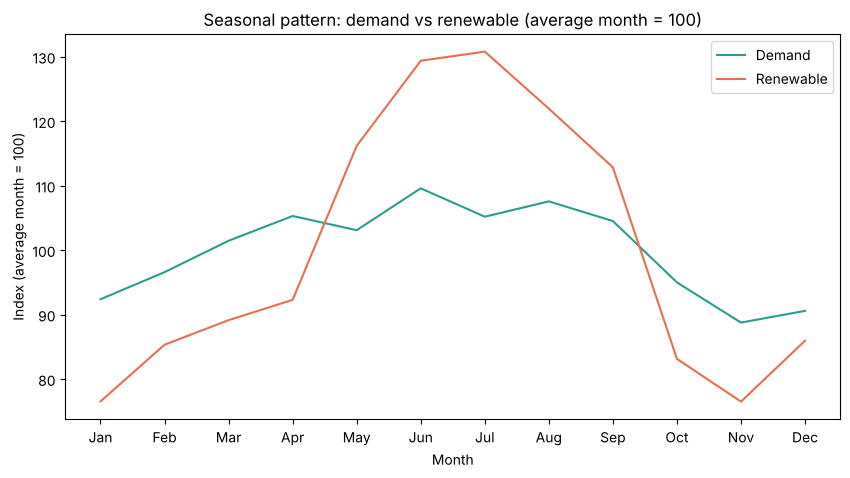

Correlation: 0.85


In [50]:
ren_recent = india.loc['2021':'2024', 'total_renewable_energy']
dem_recent = df.loc['2021':'2024', 'Total Consumption']

monthly_ren = ren_recent.groupby(ren_recent.index.month).mean()
monthly_dem = dem_recent.groupby(dem_recent.index.month).mean()

# scale each series so its average month = 100, so the two can share one chart
idx = pd.DataFrame({'Demand': monthly_dem / monthly_dem.mean() * 100,
                    'Renewable': monthly_ren / monthly_ren.mean() * 100})

idx.plot(figsize=(10, 5), title='Seasonal pattern: demand vs renewable (average month = 100)')
plt.xlabel('Month')
plt.ylabel('Index (average month = 100)')
plt.xticks(range(1, 13), ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
plt.savefig('images/seasonal_demand_vs_renewable.png', dpi=150, bbox_inches='tight')
plt.show()
print('Correlation:', round(np.corrcoef(idx['Demand'], idx['Renewable'])[0, 1], 2))

Both peak in mid-year, and their monthly patterns are strongly related (correlation about 0.85 across the 12 months, a rough indicator with so few points). Renewable output is **much more seasonal** than demand: it ranges from about 77 to 131 on the index, against about 89 to 110 for demand. Renewables sit below demand's pattern from January to April and above it from May to September, so their share of demand is lowest in the first months of the year.

## 2.7 Renewable share of demand by state (Jan to Sep 2024)

In [51]:
# Same window for both datasets: 2024 demand covers Jan-Sep, so cut the renewable data to the same dates
r24 = states[(states['date'] >= '2024-01-01') & (states['date'] <= '2024-09-29')]
ren_state = r24.groupby('state_name')['total_renewable_energy'].mean()
ren_state = ren_state.rename({'Uttar Pradesh': 'UP', 'Madhya Pradesh': 'MP'})    # match the demand file's names

dem_state = df.loc['2024'].drop(columns='Total Consumption').mean()
top10 = dem_state.sort_values(ascending=False).head(10)     # top 10 by 2024 demand (same 10 states as top_10 above)

share = (ren_state[top10.index] / dem_state[top10.index] * 100).sort_values(ascending=False).round(1)
share

Rajasthan         48.9
Karnataka         31.4
Gujarat           28.3
Tamil Nadu        24.7
Andhra Pradesh    21.4
MP                10.3
Telangana          7.9
Maharashtra        6.7
Punjab             2.9
UP                 2.6
dtype: float64

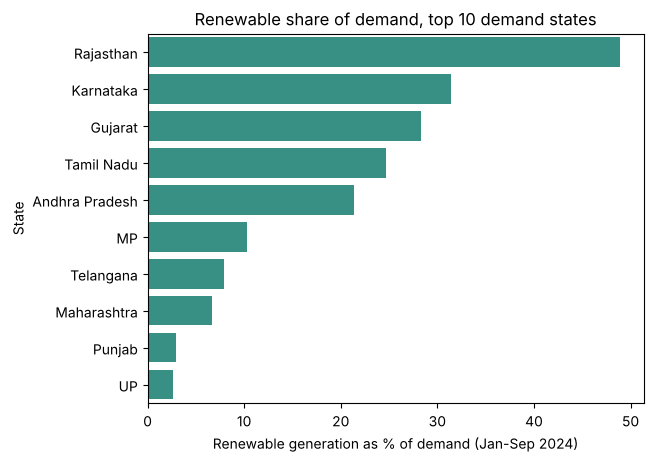

In [52]:
sb.barplot(x=share.values, y=share.index, color=palette[0])
plt.xlabel('Renewable generation as % of demand (Jan-Sep 2024)')
plt.ylabel('State')
plt.title('Renewable share of demand, top 10 demand states')
plt.savefig('images/renewable_share_by_state.png', dpi=150, bbox_inches='tight')
plt.show()

Renewable generation as a share of demand varies widely across the ten largest-demand states. **Rajasthan (48.9%), Karnataka (31.4%), Gujarat (28.3%), Tamil Nadu (24.7%) and Andhra Pradesh (21.4%)** are well above the rest, while **MP (10.3%), Telangana (7.9%), Maharashtra (6.7%), Punjab (2.9%) and UP (2.6%)** are low. Maharashtra, the largest consumer, has a low share, which suggests the largest room to add capacity. The shares are indicative only: generation and consumption come from different datasets, states trade power, and a low share can reflect limited resources or grid constraints as well as an opportunity.

---
# Part 3: Conclusions and limitations
## What the data shows
1. **Demand is growing fast and accelerating.** Average daily consumption rose about 69% from 2013 to 2024 (about 4.9% a year), with a COVID dip in 2020 and growth of about 8 to 10.5% a year in 2021 to 2023.
2. **Demand is seasonal, but differently by state.** The national peak is around June, but Punjab and UP swing the most, the southern states peak in March to April, and MP peaks in winter.
3. **Renewables are growing faster than demand, led by solar,** but still cover only about 12% of demand and about 22% of its growth.
4. **Renewable generation is concentrated.** Four states produce about 72% of it, while several of the largest consumers (Maharashtra, UP, Punjab, Telangana, MP) have shares of about 10% or less.
5. **Implication for a renewable company:** the largest headroom is in big-demand states with low renewable shares, with Maharashtra the clearest case. Renewable output peaks in June to August, so timing (and storage or other sources for the early months of the year) matters in the states whose demand peaks in March to April.

## Limitations
- **Missing data.** The demand file lacks 578 days (including January to March 2023) and the renewable file 83 days (mostly February to March 2020). Gaps were not filled.
- **Reporting changes.** Five small entities in the demand file (DD, DNH, Essar steel, Pondy, Tripura) stop reporting or have long gaps; they are small and not in the top 10, and `Total Consumption` still appears to include them, but the source's method was not checked.
- **Two separate datasets.** Demand is consumption and the renewable file is generation; they were not independently reconciled, and the units were not confirmed. Shares are indicators, not official figures.
- **No demand-supply balance.** Consumption is not unmet demand, and states trade power, so state shares do not prove how much a state could or should generate.
- **No weather, land, grid or policy data,** which also drive real capacity decisions.
- The patterns are descriptive: they show what happened, not why.

## Possible extensions
- Formal hypothesis tests (for example summer vs winter demand, or monsoon vs other months for renewables).
- State-level monthly renewable output, to check whether each state's timing matches its own demand peak.
- Shortage data (peak and energy shortage) to measure unmet demand directly.
- Weather data (temperature, rainfall) to test the weather explanations suggested above.